# Assignment 2 Object Localization 


## 1. Imports


In [22]:
import os
import json
import random
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader, random_split

from torchvision.transforms import functional as F
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou

from tqdm import tqdm


## 2. Configuration

This configuration matches the project structure:

- `data/detection/annotations`
- `data/detection/images`
- `data/raw_mushrooms`

The raw dataset is used as a fallback when the exact annotated filename is not present in `data/detection/images`.


In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

PROJECT_ROOT = Path.cwd()

ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
STEP5_DIR = ARTIFACTS_DIR / "step5_object_localization"
STEP5_MODELS_DIR = STEP5_DIR / "models"
STEP5_REPORTS_DIR = STEP5_DIR / "reports"

for output_dir in [STEP5_MODELS_DIR, STEP5_REPORTS_DIR]:
    output_dir.mkdir(parents=True, exist_ok=True)

DETECTION_DIR = PROJECT_ROOT / "data" / "detection"
IMAGES_DIR = DETECTION_DIR / "images"
ANN_DIR = DETECTION_DIR / "annotations"
RAW_DIR = PROJECT_ROOT / "data" / "raw_mushrooms"

ANNOTATION_FILES = {
    "Mushroom Agaricus": ANN_DIR / "_agaricus.coco.json",
    "Mushroom Amanita": ANN_DIR / "mushroom_amanita_annotations.json",
    "Mushroom Boletus": ANN_DIR / "mushroom_boletus_annotations.json",
    "Mushroom Entoloma": ANN_DIR / "_entoloma.coco.json",
    "Mushroom Lactarius": ANN_DIR / "mushroom_lactarius_annotations.json",
    "Mushroom Russula": ANN_DIR / "mushroom_russula_annotations.json",
}

CLASS_NAMES = [
    "background",
    "Mushroom Agaricus",
    "Mushroom Amanita",
    "Mushroom Boletus",
    "Mushroom Entoloma",
    "Mushroom Lactarius",
    "Mushroom Russula",
]

CLASS_TO_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

TARGET_SIZE = (384, 384)

# use only part of the dataset for a fast first run
MAX_RECORDS = 200

BATCH_SIZE = 2
NUM_EPOCHS = 2

print("Detection images dir exists:", IMAGES_DIR.exists())
print("Annotations dir exists:", ANN_DIR.exists())
print("Raw dir exists:", RAW_DIR.exists())
print("Target size:", TARGET_SIZE)
print("Max records:", MAX_RECORDS)
print("Epochs:", NUM_EPOCHS)


Device: cpu
Detection images dir exists: True
Annotations dir exists: True
Raw dir exists: False
Target size: (384, 384)
Max records: 200
Epochs: 2


## 2.1 Annotation tool and format choice

For the dataset preparation, annotation files from several group members were combined. Some parts of the dataset were annotated by classmates, while additional annotations and adjustments were done individually to make sure that all classes were represented and that the files followed the same structure.

The final dataset therefore consists of several COCO-style annotation files describing mushroom images and their bounding boxes. For example, the Boletus annotations file contains image metadata and object annotations in the standard COCO structure , and similar structures appear in the other annotation files used in the project .

Using COCO format is practical for this task because it is widely supported and can be directly used with PyTorch and TorchVision detection models.


## 3. Robust image path resolution

Some annotation files contain Roboflow-export names such as:

- `Mushroom_Entoloma_330_jpg.rf....jpg`

while the local raw dataset may contain the original filename:

- `Mushroom_Entoloma_330.jpg`

This resolver tries:
1. exact `file_name`
2. `extra.name`
3. recursive search in `data/detection/images`
4. recursive search in `data/raw_mushrooms`


In [3]:
def resolve_image_path(image_info, images_dir: Path, raw_dir: Path):
    candidates = []

    file_name = image_info.get("file_name")
    extra_name = image_info.get("extra", {}).get("name")

    if file_name:
        candidates.append(file_name)
    if extra_name and extra_name not in candidates:
        candidates.append(extra_name)

    for name in candidates:
        path = images_dir / name
        if path.exists():
            return path

    for name in candidates:
        matches = list(images_dir.rglob(name))
        if matches:
            return matches[0]

    for name in candidates:
        matches = list(raw_dir.rglob(name))
        if matches:
            return matches[0]

    return None


## 4. Load and merge annotations

The annotations are merged into a single list of training records. Images that cannot be resolved are skipped instead of crashing the pipeline.


In [4]:
def load_and_merge_coco_annotations(annotation_files, images_dir, raw_dir):
    merged_records = []
    skipped = []

    for class_name, json_path in annotation_files.items():
        with open(json_path, "r", encoding="utf-8") as f:
            coco = json.load(f)

        images = coco.get("images", [])
        annotations = coco.get("annotations", [])

        anns_by_image = defaultdict(list)
        for ann in annotations:
            anns_by_image[ann["image_id"]].append(ann)

        for img in images:
            image_id = img["id"]
            image_annotations = anns_by_image.get(image_id, [])
            resolved_path = resolve_image_path(img, images_dir, raw_dir)

            if resolved_path is None:
                skipped.append({
                    "class_name": class_name,
                    "json_file": str(json_path),
                    "file_name": img.get("file_name"),
                    "extra_name": img.get("extra", {}).get("name"),
                })
                continue

            merged_records.append({
                "resolved_path": str(resolved_path),
                "annotated_file_name": img.get("file_name"),
                "original_file_name": img.get("extra", {}).get("name"),
                "ann_width": img["width"],
                "ann_height": img["height"],
                "class_name": class_name,
                "class_id": CLASS_TO_ID[class_name],
                "annotations": image_annotations,
            })

    return merged_records, skipped


records, skipped_records = load_and_merge_coco_annotations(
    ANNOTATION_FILES,
    IMAGES_DIR,
    RAW_DIR
)

print("Usable annotated images before limiting:", len(records))
print("Skipped images:", len(skipped_records))
if skipped_records[:3]:
    print("First skipped examples:")
    for item in skipped_records[:3]:
        print(item)


Usable annotated images before limiting: 3781
Skipped images: 1463
First skipped examples:
{'class_name': 'Mushroom Agaricus', 'json_file': 'c:\\Users\\chupr\\Desktop\\projects\\deep-learning-minor-assignment-2\\data\\detection\\annotations\\_agaricus.coco.json', 'file_name': 'Mushroom_Agaricus_3_jpg.rf.cJzbYYIhBNn9PRo496gk.jpg', 'extra_name': 'Mushroom_Agaricus_3.jpg'}
{'class_name': 'Mushroom Agaricus', 'json_file': 'c:\\Users\\chupr\\Desktop\\projects\\deep-learning-minor-assignment-2\\data\\detection\\annotations\\_agaricus.coco.json', 'file_name': 'Mushroom_Agaricus_287_jpg.rf.fFCh9FkM5Q9vOBHr81re.jpg', 'extra_name': 'Mushroom_Agaricus_287.jpg'}
{'class_name': 'Mushroom Agaricus', 'json_file': 'c:\\Users\\chupr\\Desktop\\projects\\deep-learning-minor-assignment-2\\data\\detection\\annotations\\_agaricus.coco.json', 'file_name': 'Mushroom_Agaricus_282_jpg.rf.kvW7yLrfcIoGGGjkT6FW.jpg', 'extra_name': 'Mushroom_Agaricus_282.jpg'}


## 5. Limit dataset size for a fast first run

This notebook intentionally trains on only part of the available annotated dataset. This makes it much more practical to test on limited hardware.


In [5]:
records = records[:MAX_RECORDS]
print("Records used for this run:", len(records))


Records used for this run: 200


## 6. Dataset class with resizing and box rescaling

All images are resized to `384 × 384`. Bounding boxes are rescaled from annotation coordinates to the resized image coordinates.


In [6]:
class MushroomDetectionDataset(Dataset):
    def __init__(self, records, transforms=None, target_size=(384, 384)):
        self.records = records
        self.transforms = transforms
        self.target_size = target_size

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        img_path = Path(rec["resolved_path"])

        image_pil = Image.open(img_path).convert("RGB")

        ann_width = rec["ann_width"]
        ann_height = rec["ann_height"]

        target_width, target_height = self.target_size
        image_pil = image_pil.resize((target_width, target_height))

        scale_x = target_width / ann_width
        scale_y = target_height / ann_height

        image = F.to_tensor(image_pil)

        boxes = []
        labels = []
        areas = []
        iscrowd = []

        for ann in rec["annotations"]:
            bbox = ann.get("bbox", None)
            if bbox is None or len(bbox) != 4:
                continue

            x, y, w, h = bbox
            if w <= 1 or h <= 1:
                continue

            x1 = x * scale_x
            y1 = y * scale_y
            x2 = (x + w) * scale_x
            y2 = (y + h) * scale_y

            x1 = max(0, min(x1, target_width - 1))
            y1 = max(0, min(y1, target_height - 1))
            x2 = max(0, min(x2, target_width - 1))
            y2 = max(0, min(y2, target_height - 1))

            if x2 <= x1 or y2 <= y1:
                continue

            boxes.append([x1, y1, x2, y2])
            labels.append(rec["class_id"])
            areas.append((x2 - x1) * (y2 - y1))
            iscrowd.append(int(ann.get("iscrowd", 0)))

        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
            areas = torch.zeros((0,), dtype=torch.float32)
            iscrowd = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes = torch.as_tensor(boxes, dtype=torch.float32)
            labels = torch.as_tensor(labels, dtype=torch.int64)
            areas = torch.as_tensor(areas, dtype=torch.float32)
            iscrowd = torch.as_tensor(iscrowd, dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx]),
            "area": areas,
            "iscrowd": iscrowd,
        }

        if self.transforms is not None:
            image, target = self.transforms(image, target)

        return image, target


## 7. Simple augmentation

A horizontal flip is used during training.


In [7]:
class DetectionTransforms:
    def __init__(self, train=False):
        self.train = train

    def __call__(self, image, target):
        if self.train and random.random() < 0.5:
            image = torch.flip(image, dims=[2])

            width = image.shape[2]
            boxes = target["boxes"]

            if len(boxes) > 0:
                old_x1 = boxes[:, 0].clone()
                old_x2 = boxes[:, 2].clone()
                boxes[:, 0] = width - old_x2
                boxes[:, 2] = width - old_x1
                target["boxes"] = boxes

        return image, target


## 8. Remove empty records

Any image that ends up with zero valid boxes after preprocessing is removed.


In [8]:
filtered_records = []

for rec in records:
    ds = MushroomDetectionDataset([rec], transforms=None, target_size=TARGET_SIZE)
    _, target = ds[0]
    if len(target["boxes"]) > 0:
        filtered_records.append(rec)

print("Records before filtering:", len(records))
print("Records after filtering:", len(filtered_records))
records = filtered_records


Records before filtering: 200
Records after filtering: 199


## 9. Train / validation / test split


In [9]:
full_size = len(records)
train_size = int(0.70 * full_size)
val_size = int(0.15 * full_size)
test_size = full_size - train_size - val_size

generator = torch.Generator().manual_seed(SEED)

train_subset, val_subset, test_subset = random_split(
    records,
    [train_size, val_size, test_size],
    generator=generator
)

train_records = [records[i] for i in train_subset.indices]
val_records = [records[i] for i in val_subset.indices]
test_records = [records[i] for i in test_subset.indices]

print("Train:", len(train_records))
print("Validation:", len(val_records))
print("Test:", len(test_records))


Train: 139
Validation: 29
Test: 31


## 10. DataLoaders


In [10]:
def collate_fn(batch):
    return tuple(zip(*batch))

train_dataset = MushroomDetectionDataset(
    train_records,
    transforms=DetectionTransforms(train=True),
    target_size=TARGET_SIZE
)

val_dataset = MushroomDetectionDataset(
    val_records,
    transforms=DetectionTransforms(train=False),
    target_size=TARGET_SIZE
)

test_dataset = MushroomDetectionDataset(
    test_records,
    transforms=DetectionTransforms(train=False),
    target_size=TARGET_SIZE
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)


## 11. Visual sanity check


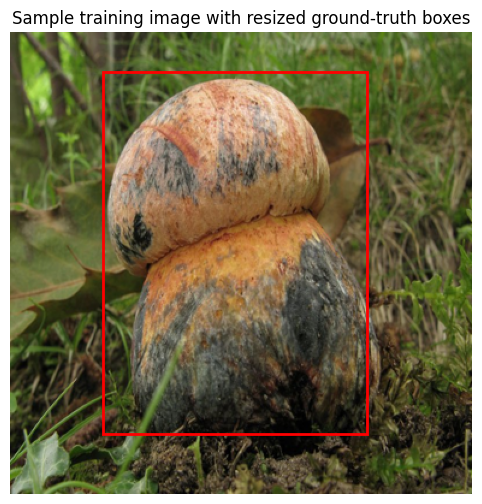

In [11]:
images, targets = next(iter(train_loader))

img = images[0]
target = targets[0]

plt.figure(figsize=(8, 6))
plt.imshow(img.permute(1, 2, 0))

for box in target["boxes"]:
    x1, y1, x2, y2 = box.tolist()
    rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=2)
    plt.gca().add_patch(rect)

plt.title("Sample training image with resized ground-truth boxes")
plt.axis("off")
plt.show()


## 12. Build R-CNN


A lightweight detector is chosen here because object localization is substantially more expensive than image classification. The model must predict both **what** object is present and **where** it is located. On limited hardware, a very heavy detector can become impractical.

R-CNN with a MobileNet-style backbone is a reasonable compromise for this assignment:

- it is a standard object detection architecture,
- it is much lighter than large ResNet-based detectors,
- it can still produce meaningful localization results on moderate hardware.

This makes the approach technically appropriate and easier to justify in the context of limited time and computational resources.

In [12]:
def get_model(num_classes):
    model = fasterrcnn_mobilenet_v3_large_320_fpn(weights="DEFAULT")

    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    return model


model = get_model(NUM_CLASSES)
model.to(DEVICE)
print("Model loaded.")


Model loaded.


## 13. Optimizer and scheduler


In [13]:
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(params, lr=1e-4)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=2, gamma=0.1)


## 14. Training loop


In [14]:
def train_one_epoch(model, loader, optimizer, device):
    model.train()
    epoch_loss = 0.0

    for images, targets in tqdm(loader):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        epoch_loss += losses.item()

    return epoch_loss / max(len(loader), 1)


## 15. Evaluation

This notebook uses a simple evaluation with:
- precision
- recall
- mean IoU

This is sufficient to verify that the detector is learning.


The evaluation metrics for object localization must differ from classification metrics because correct class prediction alone is not sufficient. A detector must also predict a bounding box that is close to the true object location.

For that reason, the evaluation focuses on metrics such as:

- **IoU (Intersection over Union)**, which measures how strongly the predicted box overlaps with the ground-truth box,
- **classification correctness**, which checks whether the predicted class label is right,
- **combined detection quality**, which depends on both class and location.

These metrics are more appropriate than plain accuracy alone, because a detector that predicts the right class but places the box in the wrong region should not be considered fully correct.

In [15]:
def evaluate_detection(model, loader, device, iou_threshold=0.5, score_threshold=0.5):
    model.eval()

    total_tp = 0
    total_fp = 0
    total_fn = 0
    iou_scores = []

    with torch.no_grad():
        for images, targets in tqdm(loader):
            images = [img.to(device) for img in images]
            outputs = model(images)

            for output, target in zip(outputs, targets):
                pred_boxes = output["boxes"].cpu()
                pred_scores = output["scores"].cpu()
                pred_labels = output["labels"].cpu()

                gt_boxes = target["boxes"].cpu()
                gt_labels = target["labels"].cpu()

                keep = pred_scores >= score_threshold
                pred_boxes = pred_boxes[keep]
                pred_labels = pred_labels[keep]

                matched_gt = set()

                for pb, pl in zip(pred_boxes, pred_labels):
                    if len(gt_boxes) == 0:
                        total_fp += 1
                        continue

                    ious = box_iou(pb.unsqueeze(0), gt_boxes).squeeze(0)
                    best_iou, best_idx = torch.max(ious, dim=0)

                    if (
                        best_iou.item() >= iou_threshold
                        and pl.item() == gt_labels[best_idx].item()
                        and best_idx.item() not in matched_gt
                    ):
                        total_tp += 1
                        matched_gt.add(best_idx.item())
                        iou_scores.append(best_iou.item())
                    else:
                        total_fp += 1

                total_fn += len(gt_boxes) - len(matched_gt)

    precision = total_tp / (total_tp + total_fp + 1e-8)
    recall = total_tp / (total_tp + total_fn + 1e-8)
    mean_iou = float(np.mean(iou_scores)) if iou_scores else 0.0

    return {
        "precision": precision,
        "recall": recall,
        "mean_iou": mean_iou,
        "tp": total_tp,
        "fp": total_fp,
        "fn": total_fn,
    }


## 16. Train the model


In [16]:
train_losses = []
val_metrics_history = []

for epoch in range(NUM_EPOCHS):
    print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")

    train_loss = train_one_epoch(model, train_loader, optimizer, DEVICE)
    train_losses.append(train_loss)

    val_metrics = evaluate_detection(
        model,
        val_loader,
        DEVICE,
        iou_threshold=0.5,
        score_threshold=0.5
    )
    val_metrics_history.append(val_metrics)

    lr_scheduler.step()

    print(f"Train loss: {train_loss:.4f}")
    print(f"Validation precision: {val_metrics['precision']:.4f}")
    print(f"Validation recall: {val_metrics['recall']:.4f}")
    print(f"Validation mean IoU: {val_metrics['mean_iou']:.4f}")



Epoch 1/2


100%|██████████| 15/15 [00:01<00:00, 10.18it/s]


Train loss: 1.5697
Validation precision: 0.9592
Validation recall: 0.8545
Validation mean IoU: 0.8384

Epoch 2/2


100%|██████████| 15/15 [00:01<00:00, 11.49it/s]

Train loss: 1.1001
Validation precision: 0.9608
Validation recall: 0.8909
Validation mean IoU: 0.8652


## 17. Plot training progress


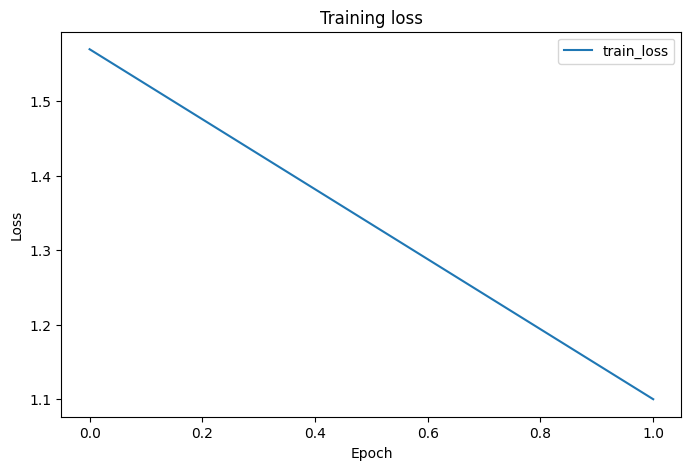

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="train_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training loss")
plt.legend()
plt.show()


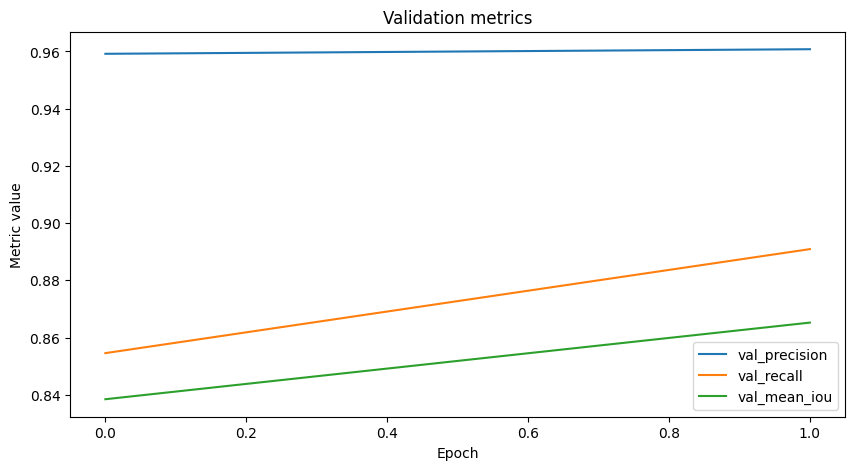

In [18]:
val_precisions = [m["precision"] for m in val_metrics_history]
val_recalls = [m["recall"] for m in val_metrics_history]
val_ious = [m["mean_iou"] for m in val_metrics_history]

plt.figure(figsize=(10, 5))
plt.plot(val_precisions, label="val_precision")
plt.plot(val_recalls, label="val_recall")
plt.plot(val_ious, label="val_mean_iou")
plt.xlabel("Epoch")
plt.ylabel("Metric value")
plt.title("Validation metrics")
plt.legend()
plt.show()


## 18. Final test evaluation


In [19]:
test_metrics = evaluate_detection(
    model,
    test_loader,
    DEVICE,
    iou_threshold=0.5,
    score_threshold=0.5
)

print("TEST METRICS")
for k, v in test_metrics.items():
    print(f"{k}: {v}")


100%|██████████| 16/16 [00:01<00:00, 10.79it/s]

TEST METRICS
precision: 0.9642857141135204
recall: 0.9310344825980975
mean_iou: 0.8595232323363975
tp: 54
fp: 2
fn: 4


## 19. Visualize predictions


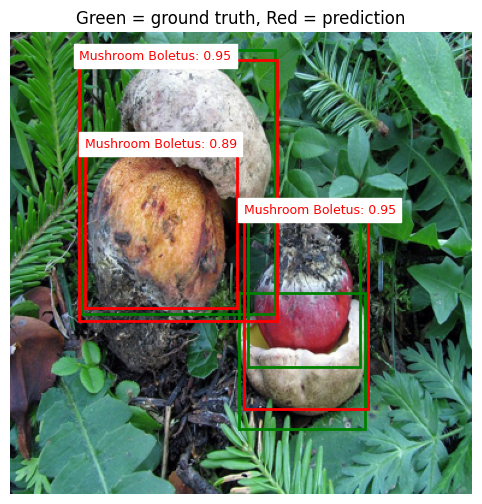

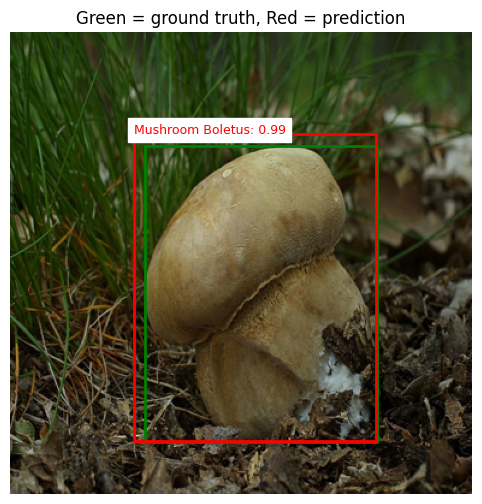

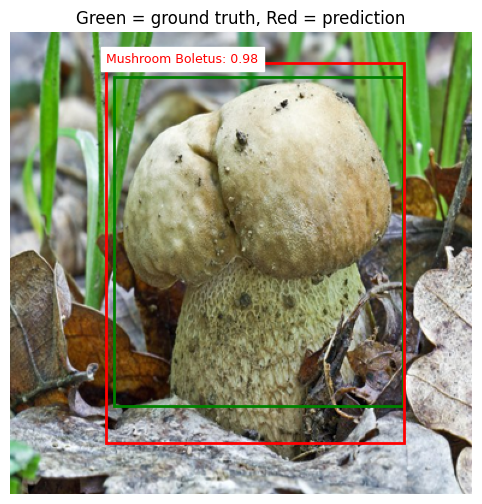

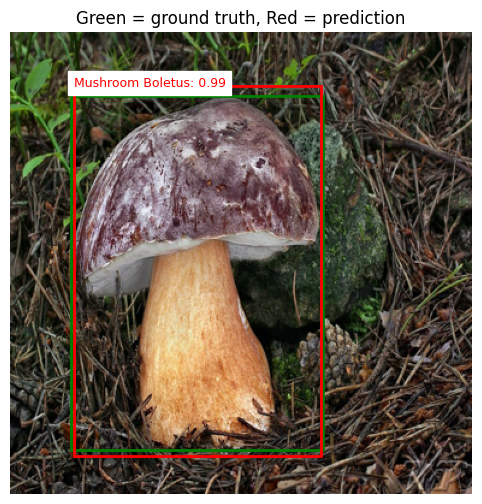

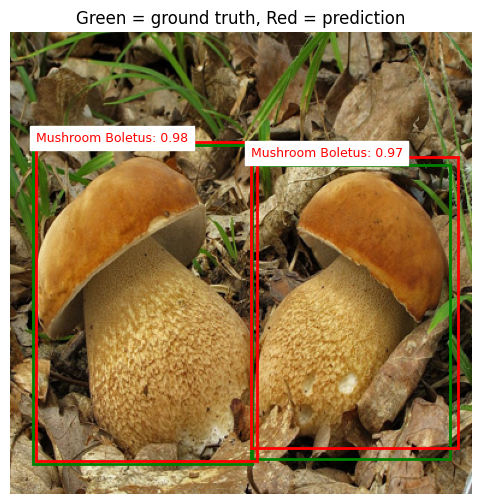

In [20]:
def visualize_predictions(model, dataset, device, class_names, num_images=5, score_threshold=0.5):
    model.eval()

    indices = random.sample(range(len(dataset)), min(num_images, len(dataset)))

    with torch.no_grad():
        for idx in indices:
            image, target = dataset[idx]
            output = model([image.to(device)])[0]

            img_np = image.permute(1, 2, 0).cpu().numpy()

            plt.figure(figsize=(8, 6))
            plt.imshow(img_np)

            for box in target["boxes"]:
                x1, y1, x2, y2 = box.tolist()
                rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="green", linewidth=2)
                plt.gca().add_patch(rect)

            for box, score, label in zip(output["boxes"].cpu(), output["scores"].cpu(), output["labels"].cpu()):
                if score < score_threshold:
                    continue

                x1, y1, x2, y2 = box.tolist()
                rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=2)
                plt.gca().add_patch(rect)

                class_name = class_names[label.item()]
                plt.text(
                    x1,
                    y1,
                    f"{class_name}: {score:.2f}",
                    color="red",
                    fontsize=9,
                    backgroundcolor="white"
                )

            plt.title("Green = ground truth, Red = prediction")
            plt.axis("off")
            plt.show()


visualize_predictions(model, test_dataset, DEVICE, CLASS_NAMES, num_images=5, score_threshold=0.5)


## 20.1 Save test metrics and a compact summary table

Saving the final metrics makes it easier to reuse them in the written report and in the final comparison section. This also improves reproducibility because the exact reported numbers are stored outside notebook outputs.


In [23]:
detection_metrics_df = pd.DataFrame([test_metrics])
detection_metrics_df.to_csv(STEP5_REPORTS_DIR / "object_localization_test_metrics.csv", index=False)
display(detection_metrics_df)


,precision,recall,mean_iou,tp,fp,fn
0,0.964286,0.931034,0.859523,54,2,4


## 21. Conclusion for the Object Localization Model

A Faster R-CNN detector with a MobileNetV3 backbone was selected because the assignment requires a model that can realistically be trained on limited hardware. This is a sensible compromise between model capacity and training cost. The detector predicts both the mushroom class and the bounding box location, so the evaluation must consider more than classification alone.

In this notebook, the main metrics are **precision**, **recall**, and **mean IoU**. Precision measures how many predicted detections are correct, recall measures how many true objects are found, and mean IoU measures how well the predicted bounding boxes overlap with the annotated boxes. These metrics are more suitable for object localization than plain classification accuracy because a detection is only useful if the class is correct **and** the location is sufficiently accurate.

To improve the score further, the most useful next steps would be: annotating more images, training for more epochs, using a larger validation set, tuning the learning rate and score threshold, and reporting mAP@IoU thresholds in addition to mean IoU if time allows.


The final interpretation of the localization model should remain realistic. In this assignment, the main question is not whether the detector reaches production quality, but whether it performs meaningfully above random behavior and whether the reported metrics demonstrate real localization ability.

A lightweight model trained on a limited annotated subset may still be a valid result if:

- the predicted boxes overlap the target objects with non-trivial IoU,
- the class predictions are often correct,
- the model performs consistently better than chance.

This is especially relevant when annotation time, dataset size, and available hardware are limited. The conclusion should therefore balance model quality with practical constraints.

## 20. Save model


In [24]:
torch.save(model.state_dict(), STEP5_MODELS_DIR / "fasterrcnn_mobilenet_mushroom_detection_light.pth")
print("Model saved to:", STEP5_MODELS_DIR / "fasterrcnn_mobilenet_mushroom_detection_light.pth")


Model saved to: c:\Users\chupr\Desktop\projects\deep-learning-minor-assignment-2\artifacts\step5_object_localization\models\fasterrcnn_mobilenet_mushroom_detection_light.pth
